# US Open Fed Spend (Aug 2026) Data Analysis with Python

# 1.) Import data

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('awards.csv')

## 2.) Load Dataset CSV from current directory

In [2]:
df.head()

,awardId,recipientName,recipientUei,awardingAgency,awardingSubAgency,awardAmount,totalOutlays,awardType,naicsCode,naicsDescription,pscCode,pscDescription,placeOfPerformanceState,placeOfPerformanceCountry,startDate,endDate,description,usaspendingUrl,scrapedAt
0,DENA0003525,NATIONAL TECHNOLOGY & ENGINEERING SOLUTIONS OF...,LUJEPCRRT377,Department of Energy,Department of Energy,4.319857e+10,2.630106e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M1JZ,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2017-01-18,2027-04-30,"IGF::CL,CT::IGF CONTRACT AWARD DE-NA0003525 TO...",https://www.usaspending.gov/award/CONT_AWD_DEN...,2026-08-30T12:40:05.714Z
1,DEAC0500OR22725,UT-BATTELLE LLC,ZLHJJ57QA2H8,Department of Energy,Department of Energy,4.243621e+10,1.481351e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M181,OPER OF GOVT R&D GOCO FACILITIES,TN,UNITED STATES,1999-10-15,2030-03-31,MANAGEMENT AND OPERATION OF THE OAK RIDGE NATI...,https://www.usaspending.gov/award/CONT_AWD_DEA...,2026-08-30T12:40:05.714Z
2,DEAC5207NA27344,"LAWRENCE LIVERMORE NATIONAL SECURITY, LLC",PM52LCJH72T9,Department of Energy,Department of Energy,4.151979e+10,1.710698e+10,DEFINITIVE CONTRACT,541710.0,"RESEARCH AND DEVELOPMENT IN THE PHYSICAL, ENGI...",AZ11,R&D- OTHER RESEARCH AND DEVELOPMENT (BASIC RES...,CA,UNITED STATES,2007-05-09,2031-09-30,TAS::89 0240::TAS THIS PERFORMANCE-BASED MANAG...,https://www.usaspending.gov/award/CONT_AWD_DEA...,2026-08-30T12:40:05.714Z
3,89233218CNA000001,"TRIAD NATIONAL SECURITY, LLC",X7WUS5LRBQU3,Department of Energy,Department of Energy,3.514494e+10,2.483692e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M1JZ,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2018-06-08,2028-10-31,IGF::CL::IGF COMPETITION FOR MANAGEMENT AND OP...,https://www.usaspending.gov/award/CONT_AWD_892...,2026-08-30T12:40:05.714Z
4,DENA0001942,"CONSOLIDATED NUCLEAR SECURITY, LLC",EWV8QKG1JUV7,Department of Energy,Department of Energy,3.465402e+10,1.818191e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M1JZ,OPERATION OF MISCELLANEOUS BUILDINGS,TN,UNITED STATES,2013-01-08,2027-09-30,"IGF::CL,CT::IGF MANAGEMENT AND OPERATING CONTR...",https://www.usaspending.gov/award/CONT_AWD_DEN...,2026-08-30T12:40:05.714Z


# 4.) Add Record number 

In [3]:
df.insert(0,'Record_Number', range(1, len(df) +1))

In [4]:
df.head()

,Record_Number,awardId,recipientName,recipientUei,awardingAgency,awardingSubAgency,awardAmount,totalOutlays,awardType,naicsCode,naicsDescription,pscCode,pscDescription,placeOfPerformanceState,placeOfPerformanceCountry,startDate,endDate,description,usaspendingUrl,scrapedAt
0,1,DENA0003525,NATIONAL TECHNOLOGY & ENGINEERING SOLUTIONS OF...,LUJEPCRRT377,Department of Energy,Department of Energy,4.319857e+10,2.630106e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M1JZ,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2017-01-18,2027-04-30,"IGF::CL,CT::IGF CONTRACT AWARD DE-NA0003525 TO...",https://www.usaspending.gov/award/CONT_AWD_DEN...,2026-08-30T12:40:05.714Z
1,2,DEAC0500OR22725,UT-BATTELLE LLC,ZLHJJ57QA2H8,Department of Energy,Department of Energy,4.243621e+10,1.481351e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M181,OPER OF GOVT R&D GOCO FACILITIES,TN,UNITED STATES,1999-10-15,2030-03-31,MANAGEMENT AND OPERATION OF THE OAK RIDGE NATI...,https://www.usaspending.gov/award/CONT_AWD_DEA...,2026-08-30T12:40:05.714Z
2,3,DEAC5207NA27344,"LAWRENCE LIVERMORE NATIONAL SECURITY, LLC",PM52LCJH72T9,Department of Energy,Department of Energy,4.151979e+10,1.710698e+10,DEFINITIVE CONTRACT,541710.0,"RESEARCH AND DEVELOPMENT IN THE PHYSICAL, ENGI...",AZ11,R&D- OTHER RESEARCH AND DEVELOPMENT (BASIC RES...,CA,UNITED STATES,2007-05-09,2031-09-30,TAS::89 0240::TAS THIS PERFORMANCE-BASED MANAG...,https://www.usaspending.gov/award/CONT_AWD_DEA...,2026-08-30T12:40:05.714Z
3,4,89233218CNA000001,"TRIAD NATIONAL SECURITY, LLC",X7WUS5LRBQU3,Department of Energy,Department of Energy,3.514494e+10,2.483692e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M1JZ,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2018-06-08,2028-10-31,IGF::CL::IGF COMPETITION FOR MANAGEMENT AND OP...,https://www.usaspending.gov/award/CONT_AWD_892...,2026-08-30T12:40:05.714Z
4,5,DENA0001942,"CONSOLIDATED NUCLEAR SECURITY, LLC",EWV8QKG1JUV7,Department of Energy,Department of Energy,3.465402e+10,1.818191e+10,DEFINITIVE CONTRACT,561210.0,FACILITIES SUPPORT SERVICES,M1JZ,OPERATION OF MISCELLANEOUS BUILDINGS,TN,UNITED STATES,2013-01-08,2027-09-30,"IGF::CL,CT::IGF MANAGEMENT AND OPERATING CONTR...",https://www.usaspending.gov/award/CONT_AWD_DEN...,2026-08-30T12:40:05.714Z


# 5.) Data Cleanup/Transformation

# A.) RENAME COLUMN TITLES 

In [5]:
df = df.rename(columns={'awardId':'award_id', 'recipientName':'recipient_name', 'awardingAgency':'awarding_agency', 'awardingSubAgency':'awarding_sub_agency','awardAmount':'award_amount', 'totalOutlays':'total_outlays', 'awardType':'award_type', 'naicsCode':'naics_code', 'naicsDescription':'naics_description', 'pscCode':'psc_code', 'pscDescription':'psc_description', 'placeOfPerformanceState':'state', 'placeOfPerformanceCountry':'country', 'startDate':'start_date', 'endDate':'end_date'})

In [6]:
df.columns

Index(['Record_Number', 'award_id', 'recipient_name', 'recipientUei',
       'awarding_agency', 'awarding_sub_agency', 'award_amount',
       'total_outlays', 'award_type', 'naics_code', 'naics_description',
       'psc_code', 'psc_description', 'state', 'country', 'start_date',
       'end_date', 'description', 'usaspendingUrl', 'scrapedAt'],
      dtype='str')

# B.) DROP UNNECESSARY COLUMNS

In [7]:
df = df.drop(columns=[ 'recipientUei', 'naics_code', 'psc_code', 'usaspendingUrl', 'scrapedAt' ])

In [8]:
df.columns

Index(['Record_Number', 'award_id', 'recipient_name', 'awarding_agency',
       'awarding_sub_agency', 'award_amount', 'total_outlays', 'award_type',
       'naics_description', 'psc_description', 'state', 'country',
       'start_date', 'end_date', 'description'],
      dtype='str')

 Columns removed: recipientUei, usaspendingUrl, scrapedAt, naics_code, psc_code


# C.) CREATE ORDINAL DATA TYPES

Add new column for contract duration days & contract length

i.) check data types of the date columns

In [9]:
df[['start_date', 'end_date']].dtypes

start_date    str
end_date      str
dtype: object

ii.) convert from string to date

In [10]:
df['start_date'] = pd.to_datetime(df['start_date'])

In [11]:
df['end_date'] = pd.to_datetime(df['end_date'])

In [12]:
df['end_date'] - df['start_date']

0        3754 days
1       11125 days
2        8910 days
3        3798 days
4        5378 days
           ...    
27724     293 days
27725    2983 days
27726      91 days
27727     365 days
27728      30 days
Length: 27729, dtype: timedelta64[us]

iii.) Re-Check data types

In [13]:
df[['start_date', 'end_date']].dtypes

start_date    datetime64[us]
end_date      datetime64[us]
dtype: object

iv.) Create new column for Contract days + Check

In [14]:
df['contract_duration_days'] = (df['end_date'] - df['start_date']).dt.days

In [15]:
df[['start_date', 'end_date', 'contract_duration_days']].head(10)

,start_date,end_date,contract_duration_days
0,2017-01-18,2027-04-30,3754.0
1,1999-10-15,2030-03-31,11125.0
2,2007-05-09,2031-09-30,8910.0
3,2018-06-08,2028-10-31,3798.0
4,2013-01-08,2027-09-30,5378.0
5,1978-09-15,2027-09-30,17912.0
6,2004-11-09,2029-09-30,9091.0
7,2005-06-01,2030-05-31,9130.0
8,2015-07-09,2030-09-30,5562.0
9,2006-07-31,2031-09-30,9192.0


v.) Create new column for Contract length + Check

In [16]:
def contract_length(days):
    if days < 3000:
        return "Short"
    elif days < 8000:
        return "Medium"
    else:
        return "Long"

In [17]:
df.columns

Index(['Record_Number', 'award_id', 'recipient_name', 'awarding_agency',
       'awarding_sub_agency', 'award_amount', 'total_outlays', 'award_type',
       'naics_description', 'psc_description', 'state', 'country',
       'start_date', 'end_date', 'description', 'contract_duration_days'],
      dtype='str')

In [18]:
df['contract_length'] = df['contract_duration_days'].apply(contract_length)

In [19]:
df.columns

Index(['Record_Number', 'award_id', 'recipient_name', 'awarding_agency',
       'awarding_sub_agency', 'award_amount', 'total_outlays', 'award_type',
       'naics_description', 'psc_description', 'state', 'country',
       'start_date', 'end_date', 'description', 'contract_duration_days',
       'contract_length'],
      dtype='str')

In [20]:
df.head()

,Record_Number,award_id,recipient_name,awarding_agency,awarding_sub_agency,award_amount,total_outlays,award_type,naics_description,psc_description,state,country,start_date,end_date,description,contract_duration_days,contract_length
0,1,DENA0003525,NATIONAL TECHNOLOGY & ENGINEERING SOLUTIONS OF...,Department of Energy,Department of Energy,4.319857e+10,2.630106e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2017-01-18,2027-04-30,"IGF::CL,CT::IGF CONTRACT AWARD DE-NA0003525 TO...",3754.0,Medium
1,2,DEAC0500OR22725,UT-BATTELLE LLC,Department of Energy,Department of Energy,4.243621e+10,1.481351e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPER OF GOVT R&D GOCO FACILITIES,TN,UNITED STATES,1999-10-15,2030-03-31,MANAGEMENT AND OPERATION OF THE OAK RIDGE NATI...,11125.0,Long
2,3,DEAC5207NA27344,"LAWRENCE LIVERMORE NATIONAL SECURITY, LLC",Department of Energy,Department of Energy,4.151979e+10,1.710698e+10,DEFINITIVE CONTRACT,"RESEARCH AND DEVELOPMENT IN THE PHYSICAL, ENGI...",R&D- OTHER RESEARCH AND DEVELOPMENT (BASIC RES...,CA,UNITED STATES,2007-05-09,2031-09-30,TAS::89 0240::TAS THIS PERFORMANCE-BASED MANAG...,8910.0,Long
3,4,89233218CNA000001,"TRIAD NATIONAL SECURITY, LLC",Department of Energy,Department of Energy,3.514494e+10,2.483692e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2018-06-08,2028-10-31,IGF::CL::IGF COMPETITION FOR MANAGEMENT AND OP...,3798.0,Medium
4,5,DENA0001942,"CONSOLIDATED NUCLEAR SECURITY, LLC",Department of Energy,Department of Energy,3.465402e+10,1.818191e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPERATION OF MISCELLANEOUS BUILDINGS,TN,UNITED STATES,2013-01-08,2027-09-30,"IGF::CL,CT::IGF MANAGEMENT AND OPERATING CONTR...",5378.0,Medium


vi.) Create ordinal data type for award size

In [21]:
df['award_amount'].describe()

count    2.772900e+04
mean     1.679088e+07
std      6.375739e+08
min      0.000000e+00
25%      1.476600e+02
50%      2.514950e+03
75%      8.959500e+04
max      4.319857e+10
Name: award_amount, dtype: float64

In [22]:
df['award_amount'].head(10)

0    4.319857e+10
1    4.243621e+10
2    4.151979e+10
3    3.514494e+10
4    3.465402e+10
5    3.085384e+10
6    2.644474e+10
7    1.992185e+10
8    1.765476e+10
9    1.748297e+10
Name: award_amount, dtype: float64

In [23]:
def award_size(amount):
    if amount < 10000:
        return "Very Low"
    elif amount < 100000:
        return "Low"
    elif amount < 1000000:
        return "Moderate"
    elif amount < 10000000:
        return "High"
    else:
        return "Very High"

In [24]:
df['award_size'] = df['award_amount'].apply(award_size)

In [25]:
df.columns

Index(['Record_Number', 'award_id', 'recipient_name', 'awarding_agency',
       'awarding_sub_agency', 'award_amount', 'total_outlays', 'award_type',
       'naics_description', 'psc_description', 'state', 'country',
       'start_date', 'end_date', 'description', 'contract_duration_days',
       'contract_length', 'award_size'],
      dtype='str')

    - Move new award_size column next to award_amount

In [26]:
award_size = df.pop('award_size')
df.insert(df.columns.get_loc('award_amount') + 1, 'award_size', award_size)

In [27]:
df.head()

,Record_Number,award_id,recipient_name,awarding_agency,awarding_sub_agency,award_amount,award_size,total_outlays,award_type,naics_description,psc_description,state,country,start_date,end_date,description,contract_duration_days,contract_length
0,1,DENA0003525,NATIONAL TECHNOLOGY & ENGINEERING SOLUTIONS OF...,Department of Energy,Department of Energy,4.319857e+10,Very High,2.630106e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2017-01-18,2027-04-30,"IGF::CL,CT::IGF CONTRACT AWARD DE-NA0003525 TO...",3754.0,Medium
1,2,DEAC0500OR22725,UT-BATTELLE LLC,Department of Energy,Department of Energy,4.243621e+10,Very High,1.481351e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPER OF GOVT R&D GOCO FACILITIES,TN,UNITED STATES,1999-10-15,2030-03-31,MANAGEMENT AND OPERATION OF THE OAK RIDGE NATI...,11125.0,Long
2,3,DEAC5207NA27344,"LAWRENCE LIVERMORE NATIONAL SECURITY, LLC",Department of Energy,Department of Energy,4.151979e+10,Very High,1.710698e+10,DEFINITIVE CONTRACT,"RESEARCH AND DEVELOPMENT IN THE PHYSICAL, ENGI...",R&D- OTHER RESEARCH AND DEVELOPMENT (BASIC RES...,CA,UNITED STATES,2007-05-09,2031-09-30,TAS::89 0240::TAS THIS PERFORMANCE-BASED MANAG...,8910.0,Long
3,4,89233218CNA000001,"TRIAD NATIONAL SECURITY, LLC",Department of Energy,Department of Energy,3.514494e+10,Very High,2.483692e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPERATION OF MISCELLANEOUS BUILDINGS,NM,UNITED STATES,2018-06-08,2028-10-31,IGF::CL::IGF COMPETITION FOR MANAGEMENT AND OP...,3798.0,Medium
4,5,DENA0001942,"CONSOLIDATED NUCLEAR SECURITY, LLC",Department of Energy,Department of Energy,3.465402e+10,Very High,1.818191e+10,DEFINITIVE CONTRACT,FACILITIES SUPPORT SERVICES,OPERATION OF MISCELLANEOUS BUILDINGS,TN,UNITED STATES,2013-01-08,2027-09-30,"IGF::CL,CT::IGF MANAGEMENT AND OPERATING CONTR...",5378.0,Medium


# D.) Addressing Nulls/Missing Values

In [28]:
df.isna().sum()

Record_Number                 0
award_id                      0
recipient_name                0
awarding_agency              21
awarding_sub_agency          21
award_amount                  0
award_size                    0
total_outlays             22244
award_type                    0
naics_description             1
psc_description               0
state                       959
country                       0
start_date                    1
end_date                      0
description                   2
contract_duration_days        1
contract_length               0
dtype: int64

# 6.) Nominal Variable: Awarding_Agency

In [29]:
df['awarding_agency'].value_counts()

awarding_agency
General Services Administration                                          16561
Department of Veterans Affairs                                            1876
Department of Justice                                                     1472
Department of Homeland Security                                           1434
Department of Health and Human Services                                   1318
Department of the Interior                                                 972
Department of Agriculture                                                  721
Department of Transportation                                               660
Department of State                                                        532
Department of Commerce                                                     420
National Aeronautics and Space Administration                              392
Department of the Treasury                                                 273
Department of Energy                

In [30]:
df['awarding_agency'].mode()

0    General Services Administration
Name: awarding_agency, dtype: str

General Services Administration is the mode of the awarding agencies, with 16561 records

create visualization:

In [31]:
top_agencies = df['awarding_agency'].value_counts().head(10).index

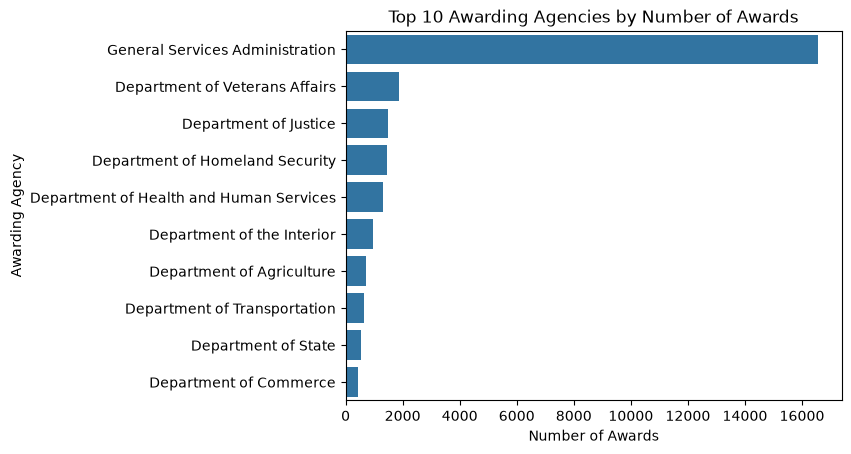

In [32]:
sns.countplot(
    data=df[df['awarding_agency'].isin(top_agencies)],
    y='awarding_agency',
    order=top_agencies
)

plt.title('Top 10 Awarding Agencies by Number of Awards')
plt.xlabel('Number of Awards')
plt.ylabel('Awarding Agency')
plt.show()

# 7.) Ordinal Variable: Contract_Length

Summary Statistics:

In [33]:
df['contract_length'].value_counts()

contract_length
Short     27576
Medium      140
Long         13
Name: count, dtype: int64

convert to %

In [34]:
df['contract_length'].value_counts(normalize=True) * 100

contract_length
Short     99.448231
Medium     0.504887
Long       0.046882
Name: proportion, dtype: float64

In [35]:
df['contract_length'].mode()

0    Short
Name: contract_length, dtype: str

Short contract lengths is the mode with 99.4% of the records falling under it

Create Visualization:

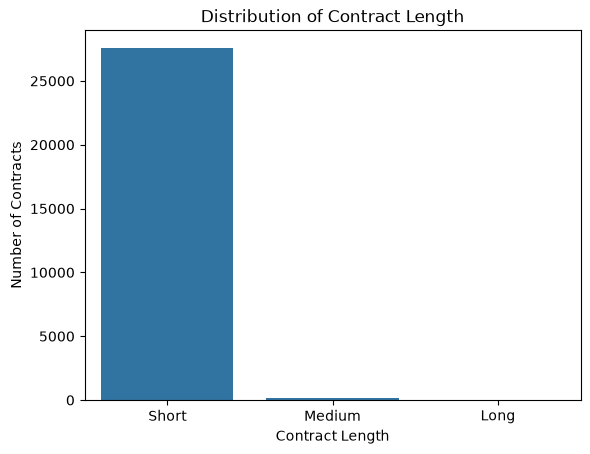

In [36]:
sns.countplot(
    data=df,
    x='contract_length',
    order=['Short', 'Medium', 'Long']
)

plt.title('Distribution of Contract Length')
plt.xlabel('Contract Length')
plt.ylabel('Number of Contracts')
plt.show()

# 8.) Interval Variable: Start_Date

extract start year

In [37]:
df['start_year'] = df['start_date'].dt.year

In [38]:
df[['start_date', 'start_year']].head()

,start_date,start_year
0,2017-01-18,2017.0
1,1999-10-15,1999.0
2,2007-05-09,2007.0
3,2018-06-08,2018.0
4,2013-01-08,2013.0


Summary Statistics:

In [39]:
df['start_year'].describe()

count    27728.000000
mean      2025.394763
std          1.753592
min       1978.000000
25%       2026.000000
50%       2026.000000
75%       2026.000000
max       2027.000000
Name: start_year, dtype: float64

In [40]:
df['start_year'].value_counts().sort_index()

start_year
1978.0        2
1987.0        1
1999.0        1
2000.0        1
2003.0        2
2004.0        2
2005.0        8
2006.0        5
2007.0        8
2008.0        9
2009.0        2
2010.0        6
2011.0        7
2012.0       12
2013.0       12
2014.0       19
2015.0       26
2016.0       25
2017.0       57
2018.0       77
2019.0      129
2020.0      207
2021.0      493
2022.0      533
2023.0      784
2024.0     1228
2025.0     1929
2026.0    22134
2027.0        9
Name: count, dtype: int64

Create visualization

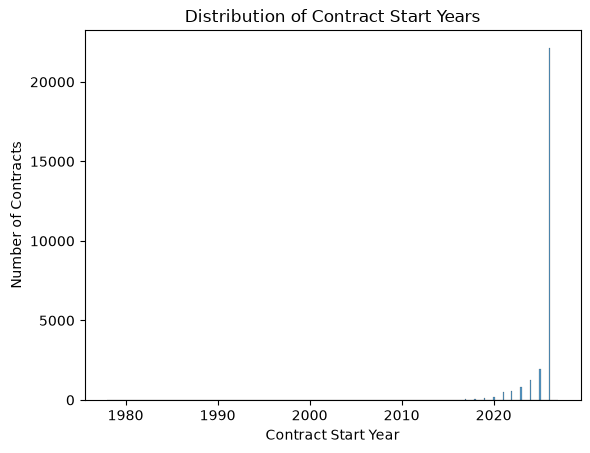

In [41]:
sns.histplot(
    data=df,
    x='start_year'
)

plt.title('Distribution of Contract Start Years')
plt.xlabel('Contract Start Year')
plt.ylabel('Number of Contracts')
plt.show()

# 9.) Ratio Variable: Award_Amount

Summary Statistics:

In [42]:
df['award_amount'].describe()

count    2.772900e+04
mean     1.679088e+07
std      6.375739e+08
min      0.000000e+00
25%      1.476600e+02
50%      2.514950e+03
75%      8.959500e+04
max      4.319857e+10
Name: award_amount, dtype: float64

Calculate the Median:

In [43]:
df['award_amount'].median()

np.float64(2514.95)

Create Visualization:

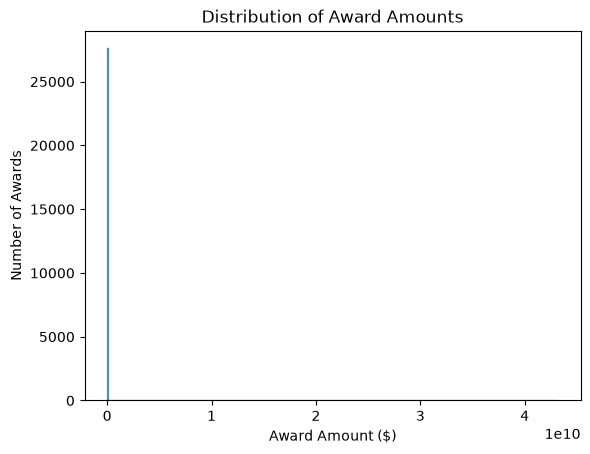

In [44]:
sns.histplot(
    data=df,
    x='award_amount'
)

plt.title('Distribution of Award Amounts')
plt.xlabel('Award Amount ($)')
plt.ylabel('Number of Awards')
plt.show()

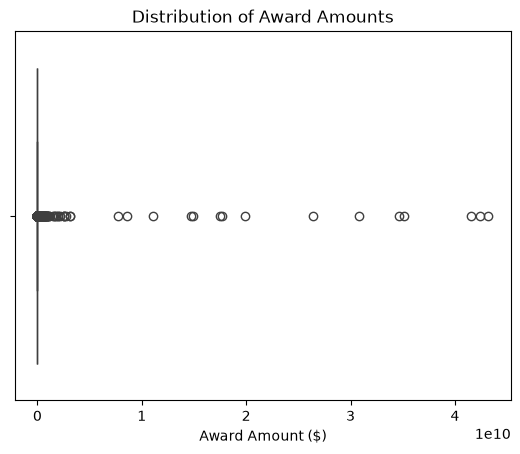

In [45]:
sns.boxplot(
    data=df,
    x='award_amount'
)

plt.title('Distribution of Award Amounts')
plt.xlabel('Award Amount ($)')
plt.show()